In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_validate, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from evalu import cv_scores, plot_curve

In [10]:
X_train = pd.read_csv("../../03.results/outputs/X_train.csv")
y_train = pd.read_csv("../../03.results/outputs/y_train.csv")
y_reg = y_train["target_next_return"]
y_clf = y_train["target_direction"]
print(X_train.shape, y_train.shape)

(1787, 40) (1787, 4)


Only X_train and y_train are loaded. The test files are intentionally untouched here.

In [11]:
kern = {}
for k in ("linear", "rbf", "poly"):
    m = Pipeline([("scaler", StandardScaler()), ("model", SVC(kernel=k, C=1.0, gamma="scale"))])
    kern[k] = cv_scores(X_train, m, y_clf, "classification")
pd.DataFrame(kern).T[["accuracy", "accuracy_std", "roc_auc", "roc_auc_std"]].round(4)

,accuracy,accuracy_std,roc_auc,roc_auc_std
linear,0.502357,0.021966,0.498124,0.03509
rbf,0.509091,0.018244,0.513459,0.02579
poly,0.491582,0.021612,0.511678,0.027486


std of target: 0.0577


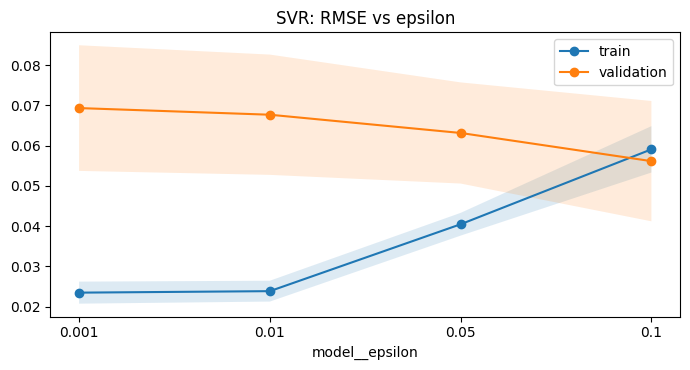

,value,train,validation
0,0.001,0.02350,0.06935
1,0.01,0.02387,0.06770
2,0.05,0.04049,0.06317
3,0.1,0.05910,0.05617


In [12]:
print("std of target:", round(y_reg.std(), 4))
reg = Pipeline([("scaler", StandardScaler()), ("model", SVR(kernel="rbf", C=1.0, epsilon=0.01))])
e = plot_curve(reg, X_train, y_reg, "model__epsilon", [0.001, 0.01, 0.05, 0.1], "neg_root_mean_squared_error", "SVR: RMSE vs epsilon", "svr_epsilon.png", flip=True)
e.round(5)

In [13]:
clf = Pipeline([("scaler", StandardScaler()), ("model", SVC(kernel="rbf", C=1.0, gamma="scale"))])
r_reg = cv_scores(X_train, reg, y_reg, "regression")
r_clf = cv_scores(X_train, clf, y_clf, "classification")
print({k: round(v, 4) for k, v in r_reg.items() if k != "task"}); print({k: round(v, 4) for k, v in r_clf.items() if k != "task"})

{'rmse': np.float64(0.0677), 'rmse_std': np.float64(0.0149), 'mae': np.float64(0.0521), 'mae_std': np.float64(0.011), 'r2': np.float64(-1.2158), 'r2_std': np.float64(1.2678)}
{'accuracy': np.float64(0.5091), 'accuracy_std': np.float64(0.0182), 'f1': np.float64(0.4926), 'f1_std': np.float64(0.1129), 'roc_auc': np.float64(0.5135), 'roc_auc_std': np.float64(0.0258)}


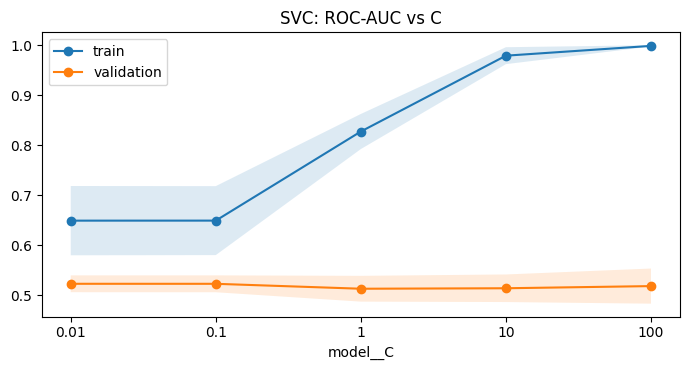

,value,train,validation
0,0.01,0.650,0.523
1,0.1,0.650,0.523
2,1,0.828,0.513
3,10,0.979,0.514
4,100,0.999,0.519


In [14]:
c = plot_curve(clf, X_train, y_clf, "model__C", [0.01, 0.1, 1, 10, 100], "roc_auc", "SVC: ROC-AUC vs C", "svc_C.png")
c.round(3)

In [15]:
rows = [{"model": "SVM", **r_reg}, {"model": "SVM", **r_clf}]
res = pd.DataFrame(rows)
res.to_csv("../../03.results/logs/model_results_svm.csv", index=False)
res.round(4)

,model,task,rmse,rmse_std,mae,mae_std,r2,r2_std,accuracy,accuracy_std,f1,f1_std,roc_auc,roc_auc_std
0,SVM,regression,0.0677,0.0149,0.0521,0.011,-1.2158,1.2678,NaN,NaN,NaN,NaN,NaN,NaN
1,SVM,classification,NaN,NaN,NaN,NaN,NaN,NaN,0.5091,0.0182,0.4926,0.1129,0.5135,0.0258


In [16]:
tscv = TimeSeriesSplit(n_splits=5)

In [17]:
svr_search = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVR()),
    ]),
    param_grid={
        "model__kernel": ["rbf", "linear"],
        "model__C": [0.1, 1.0, 10.0, 100.0],
        "model__epsilon": [0.001, 0.01, 0.05, 0.1],
        "model__gamma": ["scale", 0.01, 0.1],
    },
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    n_jobs=-1,
    refit=True,
)

In [18]:
svr_search.fit(X_train, y_reg)
tuned_reg = svr_search.best_estimator_

In [19]:
svc_search = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True)),
    ]),
    param_grid={
        "model__kernel": ["rbf", "linear", "poly"],
        "model__C": [0.1, 1.0, 10.0, 100.0],
        "model__gamma": ["scale", 0.01, 0.1],
        "model__degree": [2, 3],
        "model__class_weight": [None, "balanced"],
    },
    scoring="roc_auc",
    cv=tscv,
    n_jobs=-1,
    refit=True,
)

In [20]:
svc_search.fit(X_train, y_clf)
tuned_clf = svc_search.best_estimator_

c:\Users\faij ahamed\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [21]:
print("Best SVR parameters:", svr_search.best_params_)
print("Best SVR RMSE:", round(-svr_search.best_score_, 6))
print("Best SVC parameters:", svc_search.best_params_)
print("Best SVC ROC-AUC:", round(svc_search.best_score_, 6))

Best SVR parameters: {'model__C': 0.1, 'model__epsilon': 0.01, 'model__gamma': 0.1, 'model__kernel': 'rbf'}
Best SVR RMSE: 0.050116
Best SVC parameters: {'model__C': 100.0, 'model__class_weight': None, 'model__degree': 3, 'model__gamma': 'scale', 'model__kernel': 'poly'}
Best SVC ROC-AUC: 0.530252


In [22]:
tuned_r_reg = cv_scores(X_train, tuned_reg, y_reg, "regression")
tuned_r_clf = cv_scores(X_train, tuned_clf, y_clf, "classification")

In [23]:
tuned_res = pd.DataFrame([
    {"model": "SVM_Tuned", **tuned_r_reg},
    {"model": "SVM_Tuned", **tuned_r_clf},
])

In [24]:
tuned_res.to_csv("../../03.results/logs/model_results_svm_tuned.csv", index=False)
tuned_res.round(4)

,model,task,rmse,rmse_std,mae,mae_std,r2,r2_std,accuracy,accuracy_std,f1,f1_std,roc_auc,roc_auc_std
0,SVM_Tuned,regression,0.0501,0.0144,0.037,0.0103,-0.0412,0.0273,NaN,NaN,NaN,NaN,NaN,NaN
1,SVM_Tuned,classification,NaN,NaN,NaN,NaN,NaN,NaN,0.5104,0.015,0.4953,0.072,0.5303,0.0303
